# RetailMind AI — exploratory data analysis

This notebook explores **observed gross sales**, not unconstrained demand. It uses the full historical period for descriptive analysis; do not use test-period findings to tune models. Run preparation first; see `data/README.md`. The dashboard is generated from the same analysis.

In [1]:
from pathlib import Path
import sys
ROOT = Path.cwd() if (Path.cwd() / 'pyproject.toml').exists() else Path.cwd().parent
sys.path.insert(0, str(ROOT / 'scripts'))
from data_exploration import analyze, create_dashboard
import matplotlib.pyplot as plt
import pandas as pd
pd.set_option('display.max_columns', 20)
frame, audit, daily, products, weekday = analyze()
print('Panel:', f'{len(frame):,}', 'product-days; products:', f'{len(products):,}')
print('Period:', daily.date.min().date(), 'to', daily.date.max().date())
print('Audit:', audit)

Panel: 2,284,620 product-days; products: 4,894
Period: 2009-12-01 to 2011-12-09
Audit: {'rows_read': 1067371, 'included_rows': 1037019, 'unclassified_or_service_codes': 4651, 'returns_or_cancellations': 22951, 'reviewed_alphabetic_product_rows': 142, 'nonpositive_quantity_or_price': 2750}


## Source and cleaning audit
The workbook contains 1,067,371 rows from two sheets. The table below shows the cleaned product-day panel, where dates between first and last recorded sale are filled with zero. Full cleaning details and source checksum are in `data/README.md`. Returns, non-product codes and nonpositive prices/quantities are excluded by the current rules.

In [2]:
display(frame.head(10))
display(pd.DataFrame(list(audit.items()), columns=['Audit category','Rows']))

,stock_code,date,quantity
0,10002,2009-12-01,12.0
1,10002,2009-12-02,0.0
2,10002,2009-12-03,7.0
3,10002,2009-12-04,73.0
4,10002,2009-12-05,0.0
5,10002,2009-12-06,49.0
6,10002,2009-12-07,2.0
7,10002,2009-12-08,12.0
8,10002,2009-12-09,0.0
9,10002,2009-12-10,1.0


,Audit category,Rows
0,rows_read,1067371
1,included_rows,1037019
2,unclassified_or_service_codes,4651
3,returns_or_cancellations,22951
4,reviewed_alphabetic_product_rows,142
5,nonpositive_quantity_or_price,2750


## Calendar patterns
Plot total gross units by day and mean units per observed date by weekday. Aggregate spikes can reflect large wholesale orders; differences are descriptive, not causal.

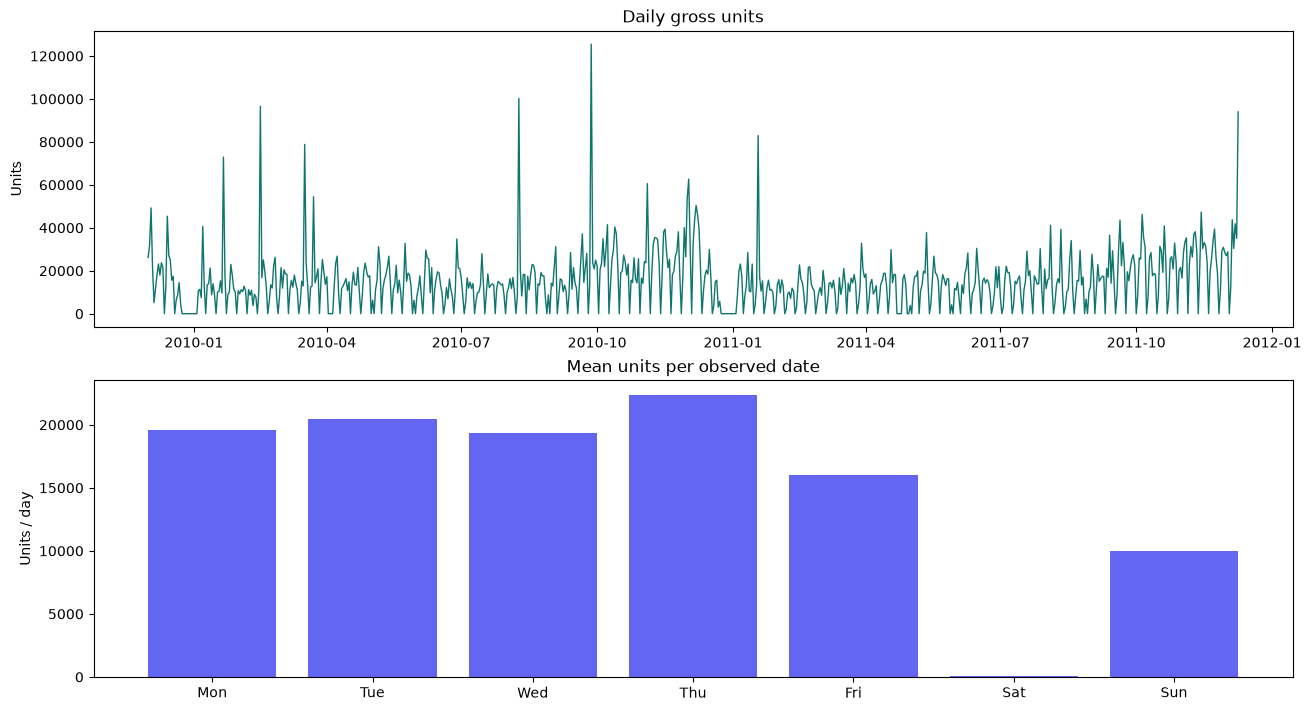

In [3]:
fig, ax = plt.subplots(2,1,figsize=(13,7),constrained_layout=True)
ax[0].plot(daily.date, daily.units, color='#0f766e', lw=1); ax[0].set(title='Daily gross units', ylabel='Units')
ax[1].bar(['Mon','Tue','Wed','Thu','Fri','Sat','Sun'], weekday.set_index('weekday').mean_units.reindex(range(7),fill_value=0), color='#6366f1'); ax[1].set(title='Mean units per observed date', ylabel='Units / day')
plt.show()

## Product concentration and intermittent sales
The table ranks retained units over the entire dataset. A zero day is an absence of recorded sales, not evidence that an item was in stock. Products are observed only between first and last recorded sales; do not interpret this as complete availability.

,stock_code,units,days,sale_days,max_daily,zero_pct,share_pct
0,84077,110138.0,739,470,6528.0,36.400541,0.965897
1,85099B,98349.0,739,589,1583.0,20.297700,0.862509
2,21212,96560.0,739,594,1540.0,19.621110,0.846820
3,85123A,96147.0,739,603,3114.0,18.403248,0.843198
4,22197,89898.0,739,563,4314.0,23.815968,0.788395
5,84879,81809.0,739,582,3359.0,21.244926,0.717455
6,23843,80995.0,1,1,80995.0,0.000000,0.710316
7,23166,78033.0,326,125,74215.0,61.656442,0.684340
8,17003,71430.0,738,301,11124.0,59.214092,0.626432
9,21977,56794.0,739,565,2724.0,23.545332,0.498077


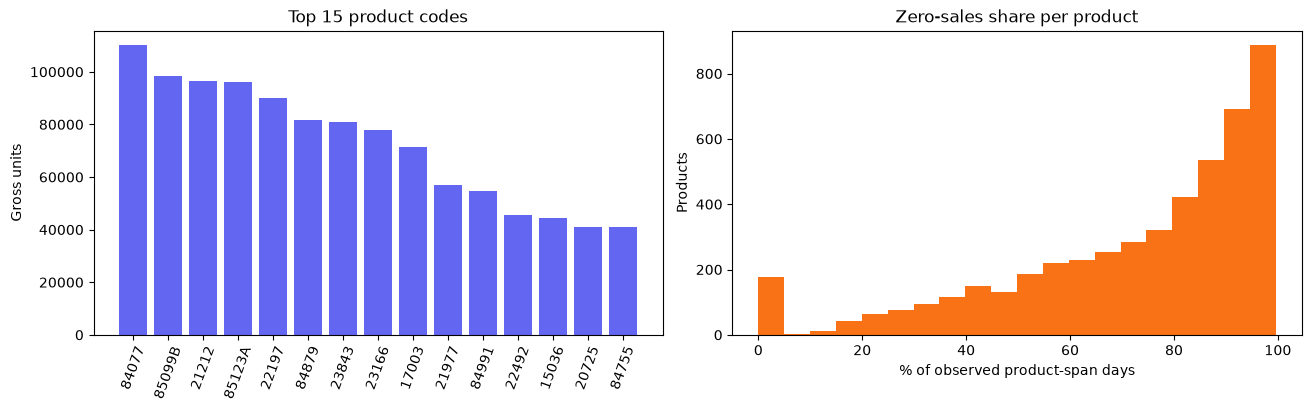

Top 10 share of units: 7.5%
Zero share of product-days: 76.7%


In [4]:
display(products.head(20))
fig, ax = plt.subplots(1,2,figsize=(13,4),constrained_layout=True)
ax[0].bar(products.head(15).stock_code, products.head(15).units, color='#6366f1'); ax[0].tick_params(axis='x',rotation=70); ax[0].set(title='Top 15 product codes',ylabel='Gross units')
ax[1].hist(products.zero_pct, bins=20, color='#f97316'); ax[1].set(title='Zero-sales share per product',xlabel='% of observed product-span days',ylabel='Products')
plt.show()
print(f'Top 10 share of units: {100*products.head(10).units.sum()/products.units.sum():.1f}%')
print(f'Zero share of product-days: {100*(frame.quantity == 0).mean():.1f}%')

## Strengths and limitations
- Large, real transaction history permits comparative SKU and rolling-origin analysis.
- Sales may be censored by stockouts; inventory levels and lost demand are absent.
- The dataset is from 2009–2011 and includes wholesale orders and extreme quantities.
- The code filter and first-to-last-sale grid are heuristics; verify source-day completeness and product eligibility.
- Full-period exploration must not be used for final test selection or tuning.

In [5]:
report = create_dashboard(frame, audit, daily, products, weekday)
print('Standalone interactive dashboard:', report)

Standalone interactive dashboard: /home/bmage/projects/retailmind-ai-forecasting/reports/data-exploration.html
